#  Diabetes Care Information Assistant
### UCS420: Cognitive Computing — Assignment 10 (Odd Roll Number Track)

**Student Name:** Aadish Jain

**Roll No.:** 1024170413

**Group:** 3Q33

---
## Project Overview
This notebook builds a **Healthcare Cognitive Assistant** that answers general information questions about **diabetes care**.
It *understands* a user's query (NLP), *identifies the intent* (machine learning), *reasons* about safety (rule engine + concept graph),
*retrieves* the most relevant facts (knowledge base) and *generates* a response.

### Architecture
```
 User query
     │
     ▼
 ┌────────────────────────┐
 │ 1. NLP pre-processing  │  lowercase → tokenise → stop-word removal → lemmatise
 └───────────┬────────────┘
             ▼
 ┌────────────────────────┐
 │ 2. Rule engine (pre)   │  R1 emergency · R2 critical glucose value · R3 small-talk · R4 unsupported query
 └───────────┬────────────┘        (if a rule fires, the assistant answers immediately)
             ▼
 ┌────────────────────────┐
 │ 3. Intent classifier   │  TF-IDF + Logistic Regression  → intent + confidence
 └───────────┬────────────┘
             ▼
 ┌────────────────────────┐
 │ 4. Rule engine (conf.) │  R5 low-confidence handling
 └───────────┬────────────┘
             ▼
 ┌────────────────────────┐
 │ 5. Knowledge retrieval │  TF-IDF cosine similarity inside the predicted intent
 └───────────┬────────────┘
             ▼
 ┌────────────────────────┐
 │ 6. Reasoning + response│  R6 dosage safeguard · R7 multi-symptom advice · concept-graph links · R8 disclaimer
 └────────────────────────┘
```

> ⚠️ **Disclaimer:** This project is an academic prototype. It gives *general educational information only* and is **not** a substitute for professional medical advice, diagnosis or treatment.

## 0. Setup — install & import libraries

In [1]:
!pip install -q nltk scikit-learn pandas matplotlib seaborn networkx ipywidgets

In [2]:
import re
import html
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

import nltk
for _pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(_pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.metrics.pairwise import cosine_similarity

from IPython.display import display, HTML, clear_output

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("✅ Libraries loaded")

✅ Libraries loaded


## 1. Labelled Corpus  *(Requirement 1)*
A labelled corpus of **112 queries across 7 intent categories** (16 per intent). Queries are written in varied styles
(questions, statements, short phrases, first-person descriptions) so the classifier does not just memorise one sentence pattern.

| Intent | Meaning |
|---|---|
| `symptoms_diagnosis` | Symptoms, types, tests and diagnosis |
| `diet_nutrition` | Food, carbohydrates, meal planning |
| `blood_glucose_monitoring` | Glucometer, targets, HbA1c, CGM |
| `medication_insulin` | Tablets, insulin types, injections, storage |
| `complications_prevention` | Eyes, kidneys, nerves, feet, heart, prevention, check-ups |
| `exercise_lifestyle` | Exercise, sleep, stress, weight, habits |
| `emergency_care` | Hypoglycaemia, DKA, severe high/low sugar |

Total queries: 112   |   Intent categories: 7


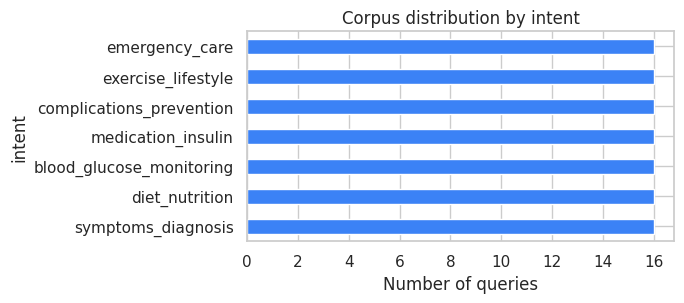

,query,intent
0,how many minutes of activity per week help blo...,exercise_lifestyle
1,how often is the hba1c test needed,blood_glucose_monitoring
2,what is the difference between rapid acting an...,medication_insulin
3,can i do yoga or strength training with diabetes,exercise_lifestyle
4,how do i lower my risk of heart disease with d...,complications_prevention
5,when should i go to the hospital for high bloo...,emergency_care
6,how do i treat low blood sugar quickly,emergency_care
7,does metformin cause stomach upset,medication_insulin


In [3]:
corpus = {
    "symptoms_diagnosis": [
        "what are the early symptoms of diabetes",
        "why do i feel very thirsty and urinate frequently",
        "how is type 2 diabetes diagnosed",
        "which blood test confirms diabetes",
        "what is the difference between type 1 and type 2 diabetes",
        "what is prediabetes and how do i know if i have it",
        "can blurred vision be a sign of high blood sugar",
        "at what glucose level is diabetes confirmed",
        "what are the signs of gestational diabetes during pregnancy",
        "i am always tired and losing weight without trying, could it be diabetes",
        "my sugar test came back borderline, does that mean i have diabetes",
        "do cuts that heal slowly point to diabetes",
        "what are the warning signs of type 1 diabetes in children",
        "is constant hunger a symptom of high blood sugar",
        "what is the oral glucose tolerance test",
        "my family has diabetes, am i likely to get it too",
    ],
    "diet_nutrition": [
        "what foods should a diabetic eat",
        "can diabetic patients eat rice and chapati",
        "which fruits are safe for people with diabetes",
        "how many carbohydrates should i eat per meal",
        "what is the glycemic index of foods",
        "is it okay to eat sweets or sugar with diabetes",
        "suggest a healthy breakfast for diabetics",
        "should i avoid fruit juice and soft drinks",
        "how does fibre help control blood sugar",
        "what is the plate method for diabetes meal planning",
        "can i drink tea or coffee with sugar if i am diabetic",
        "are oats and millets good for people with high sugar",
        "what snacks can i have between meals with diabetes",
        "is white bread worse than brown bread for blood sugar",
        "how many calories should a diabetic eat in a day",
        "can diabetics eat eggs, paneer or nuts",
    ],
    "blood_glucose_monitoring": [
        "how often should i check my blood sugar",
        "what is a normal blood sugar level after eating",
        "how do i use a glucometer at home",
        "what is hba1c and what should my target be",
        "what is a continuous glucose monitor",
        "what is the target blood glucose range before meals",
        "when is the best time to test my glucose",
        "how can i keep a log of my sugar readings",
        "why is my fasting sugar high in the morning",
        "what does time in range mean on a cgm",
        "what is the normal fasting glucose range",
        "how do i read my glucometer result",
        "how often is the hba1c test needed",
        "should i test my sugar at bedtime",
        "how do i know if my sugar readings are well controlled",
        "can a cgm replace finger prick tests",
    ],
    "medication_insulin": [
        "what does metformin do and when should i take it",
        "how do i inject insulin correctly",
        "what are the different types of insulin",
        "what are the side effects of diabetes tablets",
        "where should insulin injections be given on the body",
        "how should i store insulin at home",
        "what should i do if i miss a dose of my medicine",
        "when do type 2 patients need insulin",
        "what is the difference between rapid acting and long acting insulin",
        "can i stop taking my diabetes medication when sugar is normal",
        "does metformin cause stomach upset",
        "how long can an opened insulin pen stay outside the fridge",
        "what is a basal bolus insulin regimen",
        "can i take my diabetes pills with food",
        "do i need to change the needle on my insulin pen every time",
        "what are glp-1 and sglt2 medicines",
    ],
    "complications_prevention": [
        "what complications can diabetes cause",
        "how does diabetes affect the eyes",
        "how can i prevent diabetic foot ulcers",
        "what is diabetic neuropathy",
        "can diabetes damage the kidneys",
        "how do i lower my risk of heart disease with diabetes",
        "how can i prevent type 2 diabetes",
        "how often should i get an eye and kidney checkup",
        "is diabetes linked to high blood pressure and cholesterol",
        "how do i take care of my feet every day",
        "can high sugar cause numbness in my feet",
        "how does diabetes harm the heart and blood vessels",
        "what tests detect kidney damage early in diabetics",
        "why do diabetics get wounds and infections on the feet",
        "which screenings and vaccines do people with diabetes need",
        "can diabetes cause blindness",
    ],
    "exercise_lifestyle": [
        "how much exercise should a diabetic do",
        "is walking good for blood sugar control",
        "can i do yoga or strength training with diabetes",
        "should i check sugar before exercising",
        "how does sleep affect diabetes",
        "how can stress change my glucose levels",
        "does smoking or alcohol affect diabetes",
        "how can i lose weight safely with diabetes",
        "what lifestyle changes help manage type 2 diabetes",
        "what is the best time to work out for diabetics",
        "is cycling or swimming safe for diabetic patients",
        "how many minutes of activity per week help blood sugar control",
        "does lack of sleep raise blood sugar",
        "can meditation or breathing exercises reduce my sugar",
        "should i quit smoking and drinking if i have diabetes",
        "how do i stay active with a desk job and diabetes",
    ],
    "emergency_care": [
        "my blood sugar is very low and i feel shaky and sweating",
        "what should i do during a hypoglycemia attack",
        "what are the signs of diabetic ketoacidosis",
        "how do i treat low blood sugar quickly",
        "my diabetic father has fainted and is not responding",
        "what is the rule of 15 for hypoglycemia",
        "what are the symptoms of dangerously high blood sugar",
        "when should i go to the hospital for high blood sugar",
        "how to use glucagon for severe low sugar",
        "i have vomiting and fruity smelling breath with high sugar",
        "what should i do if my sugar goes above 300",
        "how to help someone with severe hypoglycemia who cannot swallow",
        "i feel dizzy and confused and my sugar might be low",
        "what is the difference between a hypoglycemia and a hyperglycemia emergency",
        "signs that high sugar has become an emergency",
        "which sugary items can i use to raise a low sugar fast",
    ],
}

df = pd.DataFrame([(q, intent) for intent, qs in corpus.items() for q in qs], columns=["query", "intent"])
print(f"Total queries: {len(df)}   |   Intent categories: {df['intent'].nunique()}")
assert len(df) >= 40 and df["intent"].nunique() >= 5   # Requirement 1 check

ax = df["intent"].value_counts().plot(kind="barh", figsize=(7, 3.2), color="#3b82f6")
ax.set_title("Corpus distribution by intent"); ax.set_xlabel("Number of queries"); plt.tight_layout(); plt.show()
display(df.sample(8, random_state=1).reset_index(drop=True))

## 2. Hierarchical Taxonomy  *(Requirement 2)*
A 2-level taxonomy with **5 major categories** and **2 sub-categories under each**. Each knowledge-base entry (Section 7) is tagged with a
`Category › Sub-category` path, and each intent is linked to the part(s) of the taxonomy it covers.

In [4]:
TAXONOMY = {
    "Diabetes Basics":            ["Types & Risk Factors", "Symptoms & Diagnosis"],
    "Nutrition & Lifestyle":      ["Diet & Meal Planning", "Physical Activity & Healthy Habits"],
    "Monitoring & Treatment":     ["Blood Glucose Monitoring", "Medication & Insulin"],
    "Complications & Prevention": ["Long-term Complications", "Prevention & Screening"],
    "Emergency Care":             ["Hypoglycemia (Low Blood Sugar)", "Hyperglycemia & DKA"],
}

# Which taxonomy leaves does each intent cover?
INTENT_TO_TAXONOMY = {
    "symptoms_diagnosis":       [("Diabetes Basics", "Types & Risk Factors"), ("Diabetes Basics", "Symptoms & Diagnosis")],
    "diet_nutrition":           [("Nutrition & Lifestyle", "Diet & Meal Planning")],
    "exercise_lifestyle":       [("Nutrition & Lifestyle", "Physical Activity & Healthy Habits")],
    "blood_glucose_monitoring": [("Monitoring & Treatment", "Blood Glucose Monitoring")],
    "medication_insulin":       [("Monitoring & Treatment", "Medication & Insulin")],
    "complications_prevention": [("Complications & Prevention", "Long-term Complications"),
                                 ("Complications & Prevention", "Prevention & Screening")],
    "emergency_care":           [("Emergency Care", "Hypoglycemia (Low Blood Sugar)"), ("Emergency Care", "Hyperglycemia & DKA")],
}

assert len(TAXONOMY) >= 4 and all(len(v) >= 2 for v in TAXONOMY.values())   # Requirement 2 check

print("DIABETES CARE TAXONOMY\n" + "=" * 60)
for i, (cat, subs) in enumerate(TAXONOMY.items(), 1):
    print(f"{i}. {cat}")
    for j, sub in enumerate(subs):
        branch = "└──" if j == len(subs) - 1 else "├──"
        linked = [k for k, v in INTENT_TO_TAXONOMY.items() if (cat, sub) in v]
        print(f"   {branch} {sub:<38} → intent: {', '.join(linked)}")

DIABETES CARE TAXONOMY
1. Diabetes Basics
   ├── Types & Risk Factors                   → intent: symptoms_diagnosis
   └── Symptoms & Diagnosis                   → intent: symptoms_diagnosis
2. Nutrition & Lifestyle
   ├── Diet & Meal Planning                   → intent: diet_nutrition
   └── Physical Activity & Healthy Habits     → intent: exercise_lifestyle
3. Monitoring & Treatment
   ├── Blood Glucose Monitoring               → intent: blood_glucose_monitoring
   └── Medication & Insulin                   → intent: medication_insulin
4. Complications & Prevention
   ├── Long-term Complications                → intent: complications_prevention
   └── Prevention & Screening                 → intent: complications_prevention
5. Emergency Care
   ├── Hypoglycemia (Low Blood Sugar)         → intent: emergency_care
   └── Hyperglycemia & DKA                    → intent: emergency_care


## 3. Domain Concepts & Relationships  *(Requirement 3)*
**14 domain concepts** and **20 relationships** form a small knowledge graph. At run-time the assistant detects the concepts mentioned in a query and
surfaces related facts from this graph (a light form of *reasoning*), e.g. *Exercise —lowers→ Blood Glucose*.

15 concepts, 20 relationships



,Subject,Relation,Object
0,Pancreas,produces,Insulin
1,Insulin,lowers,Blood Glucose
2,Diabetes,is_characterised_by,Hyperglycemia
3,Diabetes,impairs_action_of,Insulin
4,HbA1c,measures_average_of,Blood Glucose
5,Metformin,treats,Diabetes
6,Metformin,improves_sensitivity_to,Insulin
7,Carbohydrates,raise,Blood Glucose
8,Exercise,lowers,Blood Glucose
9,Exercise,improves_sensitivity_to,Insulin


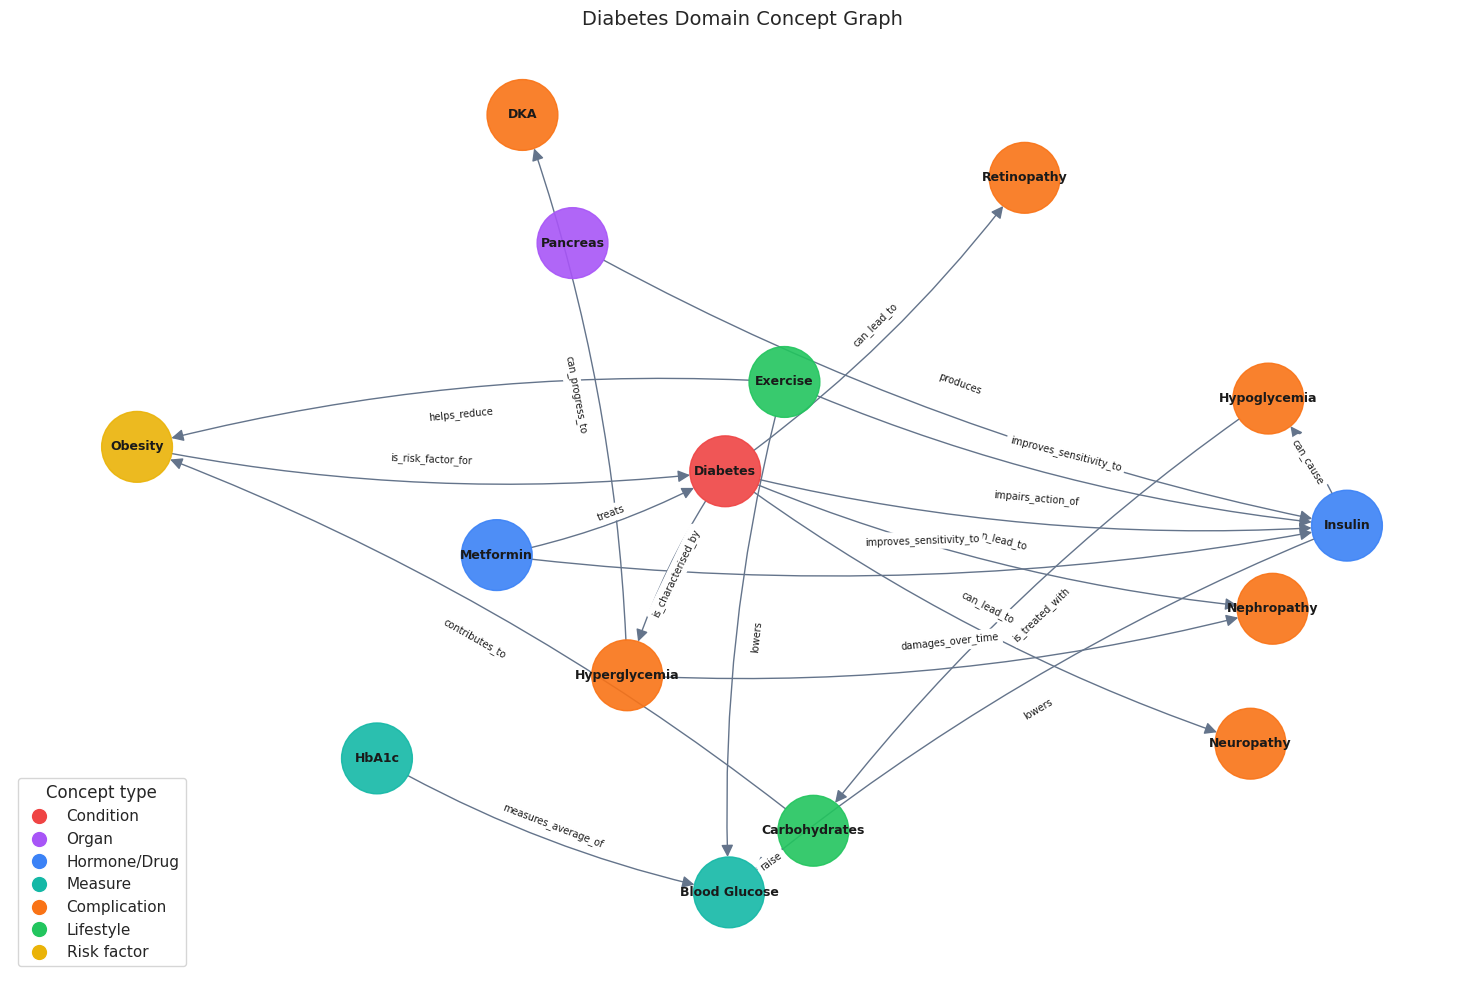

In [5]:
CONCEPTS = {  # name: (group, description)
    "Diabetes":       ("Condition",    "Chronic condition in which the body cannot regulate blood glucose properly"),
    "Pancreas":       ("Organ",        "Organ that produces insulin"),
    "Insulin":        ("Hormone/Drug", "Hormone (and medicine) that moves glucose from blood into cells"),
    "Blood Glucose":  ("Measure",      "Concentration of sugar in the blood"),
    "HbA1c":          ("Measure",      "Average blood glucose over about 2-3 months"),
    "Hypoglycemia":   ("Complication", "Dangerously low blood glucose (below 70 mg/dL)"),
    "Hyperglycemia":  ("Complication", "High blood glucose"),
    "DKA":            ("Complication", "Diabetic ketoacidosis - a life-threatening emergency"),
    "Metformin":      ("Hormone/Drug", "First-line tablet for type 2 diabetes"),
    "Carbohydrates":  ("Lifestyle",    "Nutrient that has the biggest effect on blood glucose"),
    "Exercise":       ("Lifestyle",    "Physical activity that improves insulin sensitivity"),
    "Obesity":        ("Risk factor",  "Excess body weight; major risk factor for type 2 diabetes"),
    "Neuropathy":     ("Complication", "Nerve damage causing tingling, numbness and foot problems"),
    "Retinopathy":    ("Complication", "Damage to the retina of the eye"),
    "Nephropathy":    ("Complication", "Damage to the kidneys"),
}

RELATIONS = [  # (subject, relation, object)
    ("Pancreas",      "produces",                "Insulin"),
    ("Insulin",       "lowers",                  "Blood Glucose"),
    ("Diabetes",      "is_characterised_by",     "Hyperglycemia"),
    ("Diabetes",      "impairs_action_of",       "Insulin"),
    ("HbA1c",         "measures_average_of",     "Blood Glucose"),
    ("Metformin",     "treats",                  "Diabetes"),
    ("Metformin",     "improves_sensitivity_to", "Insulin"),
    ("Carbohydrates", "raise",                   "Blood Glucose"),
    ("Exercise",      "lowers",                  "Blood Glucose"),
    ("Exercise",      "improves_sensitivity_to", "Insulin"),
    ("Obesity",       "is_risk_factor_for",      "Diabetes"),
    ("Insulin",       "can_cause",               "Hypoglycemia"),
    ("Hypoglycemia",  "is_treated_with",         "Carbohydrates"),
    ("Hyperglycemia", "can_progress_to",         "DKA"),
    ("Diabetes",      "can_lead_to",             "Neuropathy"),
    ("Diabetes",      "can_lead_to",             "Retinopathy"),
    ("Diabetes",      "can_lead_to",             "Nephropathy"),
    ("Hyperglycemia", "damages_over_time",       "Nephropathy"),
    ("Exercise",      "helps_reduce",            "Obesity"),
    ("Carbohydrates", "contributes_to",          "Obesity"),
]
assert len(CONCEPTS) >= 8 and len(RELATIONS) >= 10      # Requirement 3 check
print(f"{len(CONCEPTS)} concepts, {len(RELATIONS)} relationships\n")
display(pd.DataFrame(RELATIONS, columns=["Subject", "Relation", "Object"]))

G = nx.DiGraph()
for name, (grp, desc) in CONCEPTS.items():
    G.add_node(name, group=grp)
for s, r, o in RELATIONS:
    G.add_edge(s, o, relation=r)

palette = {"Condition": "#ef4444", "Organ": "#a855f7", "Hormone/Drug": "#3b82f6", "Measure": "#14b8a6",
           "Complication": "#f97316", "Lifestyle": "#22c55e", "Risk factor": "#eab308"}
pos = nx.spring_layout(G, seed=7, k=1.6)
plt.figure(figsize=(15, 10))
nx.draw_networkx_nodes(G, pos, node_size=2600, node_color=[palette[G.nodes[n]["group"]] for n in G], alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=18, edge_color="#64748b", node_size=2600, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "relation"), font_size=7, label_pos=0.5)
plt.legend(handles=[plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=12, label=g) for g, c in palette.items()],
           loc="lower left", title="Concept type")
plt.title("Diabetes Domain Concept Graph", fontsize=14); plt.axis("off"); plt.tight_layout(); plt.show()

## 4. NLP Pre-processing  *(Requirement 4)*
Pipeline: **lowercase → tokenisation → stop-word removal → lemmatisation** (plus removal of punctuation and a small domain-synonym normalisation step so
that *tablet / pill / medication* all map to one token). Negations and the words *low* / *high* are kept because they carry clinical meaning.

In [6]:
LEMMATIZER = WordNetLemmatizer()
STOP_WORDS = set(stopwords.words("english")) - {"no", "not", "low", "high"}
STOP_WORDS |= {"please", "tell", "know", "want", "would", "could", "also", "like", "okay", "ok", "hi", "hello"}

SYNONYMS = {"medication": "medicine", "tablet": "medicine", "pill": "medicine", "drug": "medicine",
            "workout": "exercise", "fibre": "fiber", "chapati": "roti", "pee": "urinate", "peeing": "urinate",
            "urination": "urinate", "thirsty": "thirst", "tired": "fatigue", "tiredness": "fatigue",
            "hypoglycaemia": "hypoglycemia", "hyperglycaemia": "hyperglycemia", "glycaemic": "glycemic"}

def lowercase(text):
    return text.lower()

def tokenize(text):
    toks = word_tokenize(text)
    return [t for t in toks if re.fullmatch(r"[a-z0-9]+", t)]          # drop punctuation / contractions

def remove_stopwords(tokens):
    return [t for t in tokens if t not in STOP_WORDS]

def lemmatize(tokens):
    out = []
    for t in tokens:
        lemma = LEMMATIZER.lemmatize(LEMMATIZER.lemmatize(t, pos="v"), pos="n")   # verb pass, then noun pass
        out.append(SYNONYMS.get(lemma, lemma))
    return out

def preprocess(text):
    """Full NLP pipeline → returns a clean, space-joined string."""
    return " ".join(lemmatize(remove_stopwords(tokenize(lowercase(text)))))

# --- step-by-step demonstration --------------------------------------------------------
demo = "What are the Side-Effects of Diabetes Tablets, and Should my Kidneys be checked?"
print("Original      :", demo)
s1 = lowercase(demo);        print("1. Lowercase  :", s1)
s2 = tokenize(s1);           print("2. Tokenised  :", s2)
s3 = remove_stopwords(s2);   print("3. No stopword:", s3)
s4 = lemmatize(s3);          print("4. Lemmatised :", s4)

df["clean"] = df["query"].apply(preprocess)
display(df[["query", "clean"]].head(6))

Original      : What are the Side-Effects of Diabetes Tablets, and Should my Kidneys be checked?
1. Lowercase  : what are the side-effects of diabetes tablets, and should my kidneys be checked?
2. Tokenised  : ['what', 'are', 'the', 'of', 'diabetes', 'tablets', 'and', 'should', 'my', 'kidneys', 'be', 'checked']
3. No stopword: ['diabetes', 'tablets', 'kidneys', 'checked']
4. Lemmatised : ['diabetes', 'medicine', 'kidney', 'check']


,query,clean
0,what are the early symptoms of diabetes,early symptom diabetes
1,why do i feel very thirsty and urinate frequently,feel thirst urinate frequently
2,how is type 2 diabetes diagnosed,type 2 diabetes diagnose
3,which blood test confirms diabetes,blood test confirm diabetes
4,what is the difference between type 1 and type...,difference type 1 type 2 diabetes
5,what is prediabetes and how do i know if i hav...,prediabetes


## 5. TF-IDF Feature Extraction & Classifier Training  *(Requirement 5)*
* **Features:** TF-IDF on unigrams + bigrams (`sublinear_tf=True`).
* **Models compared:** Multinomial Naïve Bayes, Logistic Regression, Linear SVM — using stratified 5-fold cross-validation.
* **Deployed model:** Logistic Regression, because it outputs class **probabilities**, which the assistant needs for its low-confidence rule.
* A stratified **75 / 25 train–test split** is held out for the final evaluation.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["intent"], test_size=0.25, stratify=df["intent"], random_state=RANDOM_STATE)
print(f"Train size: {len(X_train)}   Test size: {len(X_test)}")

def make_pipeline(clf):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)), ("clf", clf)])

candidates = {
    "Naive Bayes":         make_pipeline(MultinomialNB(alpha=0.1)),
    "Logistic Regression": make_pipeline(LogisticRegression(C=10, max_iter=2000)),
    "Linear SVM":          make_pipeline(LinearSVC(C=1.0)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, pipe in candidates.items():
    cv_acc = cross_val_score(pipe, df["clean"], df["intent"], cv=cv, scoring="accuracy")
    cv_f1  = cross_val_score(pipe, df["clean"], df["intent"], cv=cv, scoring="f1_macro")
    pipe.fit(X_train, y_train)
    rows.append({"Model": name, "CV accuracy (mean)": cv_acc.mean(), "CV accuracy (std)": cv_acc.std(),
                 "CV macro-F1": cv_f1.mean(), "Test accuracy": accuracy_score(y_test, pipe.predict(X_test))})
comparison = pd.DataFrame(rows).set_index("Model").round(3)
display(comparison)

# Inspect the TF-IDF representation of one query
tfidf_demo = candidates["Logistic Regression"].named_steps["tfidf"]
vec = tfidf_demo.transform([preprocess("how often should i check my blood sugar")])
top_terms = sorted(zip(tfidf_demo.get_feature_names_out()[vec.nonzero()[1]], vec.data), key=lambda x: -x[1])[:6]
print("\nTop TF-IDF terms for 'how often should i check my blood sugar':")
for term, w in top_terms:
    print(f"   {term:<22} {w:.3f}")
print(f"\nVocabulary size (uni+bigrams): {len(tfidf_demo.get_feature_names_out())}")

Train size: 84   Test size: 28


,CV accuracy (mean),CV accuracy (std),CV macro-F1,Test accuracy
Model,,,,
Naive Bayes,0.689,0.057,0.667,0.643
Logistic Regression,0.653,0.061,0.631,0.643
Linear SVM,0.662,0.067,0.643,0.643



Top TF-IDF terms for 'how often should i check my blood sugar':
   check blood            0.453
   often                  0.453
   often check            0.453
   check                  0.415
   blood sugar            0.300
   blood                  0.275

Vocabulary size (uni+bigrams): 454


## 6. Model Evaluation  *(Requirement 6)*
Accuracy, precision, recall, F1-score (per-class, macro and weighted) and a confusion matrix on the **held-out test set**, for all three models, followed by a detailed view of the deployed model.

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Naive Bayes,0.643,0.674,0.643,0.652
Logistic Regression,0.643,0.695,0.643,0.658
Linear SVM,0.643,0.695,0.643,0.658



DETAILED CLASSIFICATION REPORT — Logistic Regression (deployed model)

                          precision    recall  f1-score   support

blood_glucose_monitoring       1.00      0.75      0.86         4
complications_prevention       1.00      0.75      0.86         4
          diet_nutrition       0.67      0.50      0.57         4
          emergency_care       0.50      0.75      0.60         4
      exercise_lifestyle       0.20      0.25      0.22         4
      medication_insulin       1.00      1.00      1.00         4
      symptoms_diagnosis       0.50      0.50      0.50         4

                accuracy                           0.64        28
               macro avg       0.70      0.64      0.66        28
            weighted avg       0.70      0.64      0.66        28



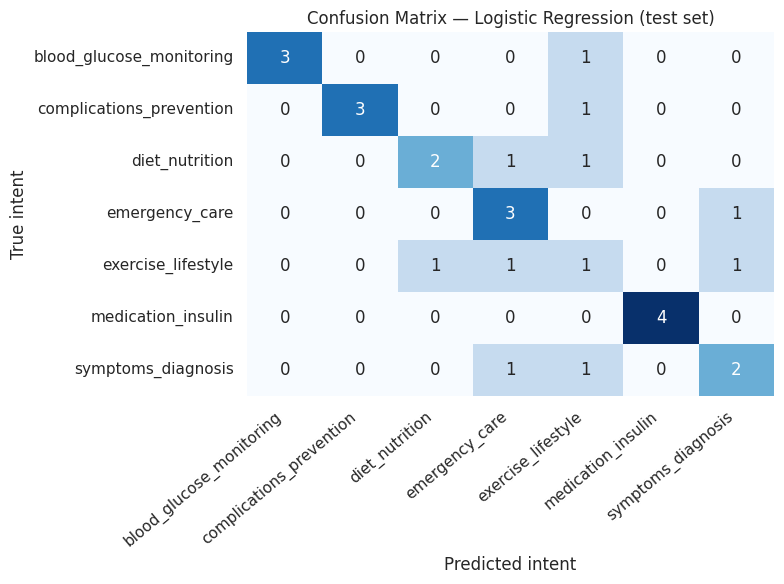

Mean confidence — correct predictions : 0.52
Mean confidence — wrong predictions   : 0.38
Lowest confidence among correct predictions: 0.24


In [8]:
summary_rows = []
for name, pipe in candidates.items():
    y_pred = pipe.predict(X_test)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    summary_rows.append({"Model": name, "Accuracy": accuracy_score(y_test, y_pred),
                         "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f})
display(pd.DataFrame(summary_rows).set_index("Model").round(3))

best = candidates["Logistic Regression"]
y_pred = best.predict(X_test)
labels = sorted(df["intent"].unique())

print("\nDETAILED CLASSIFICATION REPORT — Logistic Regression (deployed model)\n")
print(classification_report(y_test, y_pred, labels=labels, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False)
plt.title("Confusion Matrix — Logistic Regression (test set)")
plt.xlabel("Predicted intent"); plt.ylabel("True intent"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

# Confidence analysis → used to choose the low-confidence threshold (Rule R5)
proba = best.predict_proba(X_test)
conf = proba.max(axis=1)
correct = (y_pred == y_test.values)
print(f"Mean confidence — correct predictions : {conf[correct].mean():.2f}")
if (~correct).any():
    print(f"Mean confidence — wrong predictions   : {conf[~correct].mean():.2f}")
print(f"Lowest confidence among correct predictions: {conf[correct].min():.2f}")

**Final training:** having validated the approach, the deployed model is re-trained on the *entire* corpus so it learns from every available example.

In [9]:
final_model = make_pipeline(LogisticRegression(C=10, max_iter=2000))
final_model.fit(df["clean"], df["intent"])
INTENTS = list(final_model.classes_)
print("✅ Final intent classifier trained on all", len(df), "queries. Intents:", INTENTS)

✅ Final intent classifier trained on all 112 queries. Intents: ['blood_glucose_monitoring', 'complications_prevention', 'diet_nutrition', 'emergency_care', 'exercise_lifestyle', 'medication_insulin', 'symptoms_diagnosis']


## 7. Domain-Specific Knowledge Base  *(Requirement 7)*
**29 curated entries** covering all 7 intent categories. Each entry has a taxonomy path, a title, retrieval keywords, an explanatory answer and key points.
Content follows widely accepted guidance (e.g. ADA *Standards of Care*, WHO and IDF materials) and is **general information, not personal medical advice**.

In [10]:
def E(category, subcategory, title, keywords, answer, points):
    return dict(category=category, subcategory=subcategory, title=title, keywords=keywords, answer=answer, points=points)

KNOWLEDGE_BASE = {
 "symptoms_diagnosis": [
  E("Diabetes Basics", "Symptoms & Diagnosis", "Common symptoms of diabetes",
    "symptoms signs warning early thirst urination hungry fatigue tired blurred vision weight loss tingling numbness wound infection",
    "Typical warning signs are increased thirst, frequent urination, extreme hunger, unexplained weight loss, tiredness, blurred vision, slow-healing cuts, frequent infections, and tingling or numbness in the hands or feet.",
    ["Type 1 diabetes symptoms usually appear over days to weeks and can be severe.",
     "Type 2 diabetes often develops slowly and may cause no symptoms for years, so regular screening matters.",
     "Symptoms are a reason to get a blood glucose test - they are not a diagnosis by themselves."]),
  E("Diabetes Basics", "Symptoms & Diagnosis", "How diabetes is diagnosed",
    "diagnosis diagnosed test confirm blood test fasting plasma glucose hba1c ogtt oral glucose tolerance level threshold",
    "Diabetes is confirmed with blood tests. Commonly used criteria: fasting plasma glucose of 126 mg/dL (7.0 mmol/L) or higher, HbA1c of 6.5% or higher, a 2-hour glucose of 200 mg/dL (11.1 mmol/L) or higher during an oral glucose tolerance test, or a random glucose of 200 mg/dL or higher together with classic symptoms.",
    ["Without clear symptoms, an abnormal result is normally repeated to confirm the diagnosis.",
     "Prediabetes range: fasting glucose 100-125 mg/dL or HbA1c 5.7-6.4%.",
     "Your doctor interprets results alongside your overall health and risk factors."]),
  E("Diabetes Basics", "Types & Risk Factors", "Types of diabetes and who is at risk",
    "type 1 type 2 difference types autoimmune insulin resistance risk factors family history overweight inactivity age",
    "Type 1 diabetes is an autoimmune condition in which the pancreas makes little or no insulin, so lifelong insulin is needed. Type 2 diabetes, the most common form, occurs when the body becomes resistant to insulin and/or cannot make enough; it is linked to excess weight, inactivity, age and family history. Gestational diabetes appears during pregnancy.",
    ["Type 1 cannot currently be prevented; type 2 can often be delayed or prevented with lifestyle change.",
     "Risk factors for type 2: overweight, family history, physical inactivity, high blood pressure, PCOS, previous gestational diabetes.",
     "Both main types need ongoing medical care and self-management."]),
  E("Diabetes Basics", "Types & Risk Factors", "Prediabetes and gestational diabetes",
    "prediabetes pre-diabetes gestational pregnancy pregnant borderline impaired glucose",
    "Prediabetes means blood glucose is higher than normal but not yet in the diabetes range. It is a warning stage - lifestyle changes can often stop progression. Gestational diabetes is high blood glucose first detected during pregnancy; screening is usually done between weeks 24 and 28.",
    ["Gestational diabetes is managed with diet, activity, glucose monitoring and sometimes insulin under medical supervision.",
     "It often resolves after delivery but raises the mother's later risk of type 2 diabetes, so follow-up testing is important.",
     "Losing 5-7% of body weight and regular activity can greatly lower progression from prediabetes."]),
 ],
 "diet_nutrition": [
  E("Nutrition & Lifestyle", "Diet & Meal Planning", "Healthy eating basics for diabetes",
    "food foods eat diet healthy vegetables whole grains protein pulses dal nuts fiber fibre avoid fried processed meal timing",
    "A diabetes-friendly diet is built around non-starchy vegetables, whole grains, pulses and legumes, lean proteins, nuts and healthy fats. Limit refined grains, sugary foods and drinks, and deep-fried or highly processed foods.",
    ["Dietary fibre slows glucose absorption - choose whole grains, pulses, vegetables and whole fruit.",
     "Eat at regular times; avoid long gaps or skipped meals, especially if you take insulin or sulfonylureas.",
     "A registered dietitian can personalise a meal plan to your medicines, culture and preferences."]),
  E("Nutrition & Lifestyle", "Diet & Meal Planning", "Carbohydrates, rice, roti and glycemic index",
    "carbohydrates carbs carb counting rice roti chapati bread glycemic index low gi portion per meal grains",
    "Carbohydrates have the biggest effect on blood glucose, so the amount and type matter. Low glycemic index (GI) foods such as oats, millets, whole wheat, pulses and most vegetables raise glucose more slowly than white rice, white bread or sugary foods.",
    ["Rice and roti are not forbidden - control the portion, prefer whole grain, and pair them with vegetables and protein.",
     "Many people aim for a consistent carbohydrate amount at each meal; a dietitian can set your personal target.",
     "Checking glucose 1-2 hours after a meal shows how a particular food affects you."]),
  E("Nutrition & Lifestyle", "Diet & Meal Planning", "Fruit, sweets, juice and sugary drinks",
    "fruit fruits juice sweets sugar dessert soft drink soda cola sweetener mango banana",
    "Whole fruit can be part of a diabetic diet in moderate portions and is a better choice than fruit juice, which has little fibre and raises glucose quickly. Sugary drinks and sweets should generally be avoided, or kept as a rare treat counted within your carbohydrate plan.",
    ["Choose fruits such as guava, apple, berries, papaya or orange in measured portions.",
     "Fruit juice and soft drinks are best kept for treating low blood sugar.",
     "Sugar substitutes may help reduce sugar intake, but check with your care team about which are suitable."]),
  E("Nutrition & Lifestyle", "Diet & Meal Planning", "Plate method and sample breakfast ideas",
    "plate method meal plan planning breakfast lunch dinner snack idea suggestion oats poha chilla eggs",
    "The plate method is a simple way to plan meals: fill half your plate with non-starchy vegetables, one quarter with lean protein (dal, paneer, egg, fish, chicken) and one quarter with whole grains or other carbohydrates.",
    ["Breakfast ideas: vegetable besan chilla, moong dal cheela, vegetable omelette, oats with nuts and seeds, or vegetable poha with peanuts.",
     "Snack ideas: roasted chana, a handful of nuts, sprouts salad, or unsweetened yoghurt.",
     "Limit alcohol and never drink it on an empty stomach if you use insulin or sulfonylureas."]),
 ],
 "blood_glucose_monitoring": [
  E("Monitoring & Treatment", "Blood Glucose Monitoring", "Blood glucose target ranges",
    "target range normal level after eating before meals fasting postprandial goal mg/dl mmol",
    "For many adults with diabetes, commonly suggested targets are 80-130 mg/dL (4.4-7.2 mmol/L) before meals and below 180 mg/dL (10 mmol/L) one to two hours after the start of a meal. A typical HbA1c goal is below 7%.",
    ["Targets are individualised - older adults or people with frequent lows may have less strict goals.",
     "Ask your doctor what range is right for you.",
     "Readings outside your range repeatedly are a reason to contact your care team."]),
  E("Monitoring & Treatment", "Blood Glucose Monitoring", "How to check glucose with a glucometer",
    "glucometer meter strip lancet finger prick how to use test home check procedure fingertip",
    "To test with a glucometer: wash and dry your hands, insert a fresh strip, prick the side of a fingertip with a lancet, touch the blood drop to the strip, and read the result. Record the value, date and time.",
    ["Use a new lancet each time (or as advised) and rotate fingers.",
     "Check that strips are in date and stored as the manufacturer instructs.",
     "Keep a log (notebook or app) of readings, meals, activity and medicines to share with your doctor."]),
  E("Monitoring & Treatment", "Blood Glucose Monitoring", "How often and when to test",
    "how often frequency when best time test check log record morning fasting high dawn phenomenon bedtime sick",
    "How often to test depends on your treatment: people on multiple daily insulin injections usually test several times a day, while those on tablets or diet alone may test less often. Common times are fasting, before meals, 1-2 hours after meals, at bedtime, before and after exercise, when unwell, and when you suspect a low.",
    ["Morning highs can be caused by the 'dawn phenomenon' (early-morning hormone surge) - discuss patterns with your doctor.",
     "Test more often when you change medicines, diet or routine, or during illness.",
     "Never adjust insulin based on a single reading unless your care team has taught you how."]),
  E("Monitoring & Treatment", "Blood Glucose Monitoring", "HbA1c and continuous glucose monitoring (CGM)",
    "hba1c a1c glycated haemoglobin cgm continuous glucose monitor sensor time in range freestyle libre dexcom",
    "HbA1c reflects your average glucose over the previous 2-3 months and is usually checked every 3-6 months. A continuous glucose monitor (CGM) uses a small sensor to read glucose every few minutes and shows trends and alarms.",
    ["'Time in range' means the share of time spent between 70 and 180 mg/dL; many adults aim for more than 70%.",
     "CGM reduces the need for finger-pricks but may still need occasional confirmation tests.",
     "HbA1c can be unreliable in anaemia and some other conditions - your doctor will advise."]),
 ],
 "medication_insulin": [
  E("Monitoring & Treatment", "Medication & Insulin", "Oral diabetes medicines (metformin and others)",
    "metformin medicine tablets pills oral side effects sulfonylurea sglt2 dpp4 glp-1 take with food nausea",
    "Metformin is usually the first medicine for type 2 diabetes; it reduces glucose production in the liver and improves insulin sensitivity. It is generally taken with meals to reduce stomach upset. Other classes include sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors and GLP-1 medicines.",
    ["Common side effects: metformin - nausea, loose stools; sulfonylureas - low blood sugar and weight gain; SGLT2 inhibitors - genital infections and dehydration.",
     "Never start, stop or change a medicine without talking to your doctor.",
     "Tell your doctor about all other medicines and any kidney problems."]),
  E("Monitoring & Treatment", "Medication & Insulin", "Types of insulin",
    "insulin types rapid acting short acting intermediate long acting basal bolus premixed difference onset when needed",
    "Insulin types differ by how quickly they start and how long they last: rapid-acting (starts in about 15 minutes, taken with meals), short-acting/regular (about 30 minutes), intermediate (NPH) and long-acting 'basal' insulin (works for up to a day or more). Premixed insulins combine two types.",
    ["People with type 1 diabetes always need insulin; people with type 2 may need it when tablets and lifestyle are no longer enough.",
     "Needing insulin is not a personal failure - type 2 diabetes is progressive.",
     "Your doctor chooses the type, timing and dose for you."]),
  E("Monitoring & Treatment", "Medication & Insulin", "Insulin injection technique and storage",
    "inject injection pen syringe needle site abdomen thigh arm rotate store storage fridge refrigerate vial",
    "Inject insulin into the fat layer under the skin - abdomen, outer thigh, upper arm or buttock - and rotate sites to prevent lumps (lipohypertrophy). Use a new needle each time. Store unopened insulin in the refrigerator (2-8 °C), never freeze it; the vial or pen in use can usually be kept at room temperature for the period stated on the label.",
    ["Keep insulin away from heat and direct sunlight, and never leave it in a hot car.",
     "Absorption is fastest from the abdomen - keep a consistent area for each time of day as advised.",
     "Check expiry dates and look for clumps or discolouration before use."]),
  E("Monitoring & Treatment", "Medication & Insulin", "Missed doses and medicine safety",
    "miss missed dose forgot skip stop medicine medication dosage units how much change adjust normal sugar",
    "If you miss a dose, follow the instructions on your medicine leaflet or ask your doctor or pharmacist - do not double the next dose unless you have been told to. Do not stop diabetes medicines just because your sugar looks normal; normal readings often mean the medicine is working.",
    ["The correct dose is personal and can only be decided by your doctor - this assistant cannot recommend doses.",
     "Medicines that can cause lows (insulin, sulfonylureas) must be balanced with meals and activity.",
     "Carry a diabetes ID card and keep a fast-acting carbohydrate with you."]),
 ],
 "complications_prevention": [
  E("Complications & Prevention", "Long-term Complications", "Long-term complications of diabetes",
    "complications damage long term problems eyes kidneys nerves heart stroke feet gums skin retinopathy nephropathy neuropathy",
    "Over many years, high glucose can damage small and large blood vessels and nerves. Main complications are retinopathy (eyes), nephropathy (kidneys), neuropathy (nerves), heart disease and stroke, foot ulcers and infections, and gum disease.",
    ["Good control of glucose, blood pressure and cholesterol greatly lowers the risk of every complication.",
     "Early damage is often painless - regular screening finds it in time to treat.",
     "Stopping smoking is one of the most powerful protective steps."]),
  E("Complications & Prevention", "Long-term Complications", "Eyes, kidneys and nerves",
    "eye eyes vision retina kidney kidneys neuropathy nerve nerves numbness tingling blood pressure cholesterol heart",
    "Diabetic retinopathy can cause vision loss without early symptoms; kidney damage (nephropathy) is silent until advanced; neuropathy causes tingling, burning pain or numbness, usually starting in the feet. Diabetes also doubles the risk of heart disease, often together with high blood pressure and abnormal cholesterol.",
    ["Aim for a blood pressure below about 130/80 mmHg unless your doctor sets a different target.",
     "Many people with diabetes take a statin to protect the heart - ask your doctor.",
     "Report new vision changes, swelling, chest discomfort or foot numbness promptly."]),
  E("Complications & Prevention", "Long-term Complications", "Daily foot care",
    "foot feet ulcer wound care shoes socks toenail blister walk barefoot daily inspect moisturise",
    "Check both feet every day for cuts, blisters, redness or swelling (use a mirror if needed). Wash and dry them well, especially between the toes, and moisturise the skin but not between the toes. Wear well-fitting shoes and socks and never walk barefoot.",
    ["Cut toenails straight across; have corns and calluses treated by a professional.",
     "See a doctor early for any wound, blister or colour change - foot problems can worsen quickly.",
     "Have your feet examined by a clinician at least once a year."]),
  E("Complications & Prevention", "Prevention & Screening", "Recommended check-ups and screening",
    "checkup check-up screening how often yearly annual eye exam kidney test urine albumin egfr lipid foot exam hba1c schedule",
    "A typical schedule: HbA1c every 3-6 months; a dilated eye exam at least once a year (or as advised); kidney tests (urine albumin and eGFR) yearly; blood pressure at every visit; cholesterol test yearly; a foot examination yearly; and dental check-ups.",
    ["Vaccinations (flu, pneumococcal, hepatitis B, COVID-19) are recommended for most people with diabetes.",
     "Bring your glucose log to every appointment.",
     "Your doctor may change the schedule based on your risk."]),
  E("Complications & Prevention", "Prevention & Screening", "Preventing type 2 diabetes and heart disease",
    "prevent prevention avoid delay reduce risk type 2 weight loss lifestyle heart disease cardiovascular cholesterol smoking",
    "Type 2 diabetes can often be prevented or delayed. In a large trial, lifestyle change (losing 5-7% of body weight and 150 minutes of activity per week) lowered the risk of developing diabetes by about 58% in high-risk adults.",
    ["Choose a diet rich in vegetables, whole grains and pulses and low in sugary drinks and processed food.",
     "Don't smoke; keep blood pressure and cholesterol in range to protect your heart.",
     "If you have prediabetes or risk factors, ask about regular glucose screening."]),
 ],
 "exercise_lifestyle": [
  E("Nutrition & Lifestyle", "Physical Activity & Healthy Habits", "How much and what kind of exercise",
    "exercise physical activity walking walk yoga strength resistance training aerobic minutes week cycling swimming how much sitting",
    "Adults with diabetes are advised to do at least 150 minutes per week of moderate aerobic activity (such as brisk walking, cycling or swimming), spread over at least three days with no more than two days in a row without activity, plus resistance (strength) training two to three times a week.",
    ["Yoga and tai chi can improve flexibility, balance and stress - they are a good addition but not a replacement for aerobic exercise.",
     "A 10-15 minute walk after meals helps lower after-meal glucose.",
     "Break up long periods of sitting every 30 minutes."]),
  E("Nutrition & Lifestyle", "Physical Activity & Healthy Habits", "Exercising safely with diabetes",
    "check sugar before exercise exercising workout safety hypoglycemia snack hydrate shoes best time ketones",
    "Check glucose before and after exercise, especially if you take insulin or sulfonylureas. If your glucose is low or dropping before activity, have a small carbohydrate snack first - ask your care team for your personal threshold. Always carry fast-acting carbohydrate.",
    ["Low blood sugar can occur during or even many hours after exercise.",
     "Avoid vigorous exercise when glucose is very high and you have ketones or feel unwell.",
     "Wear proper footwear, inspect your feet afterwards, and stay hydrated."]),
  E("Nutrition & Lifestyle", "Physical Activity & Healthy Habits", "Sleep, stress, smoking and alcohol",
    "sleep stress smoking smoke alcohol drink tobacco cortisol insomnia habits relaxation lifestyle changes",
    "Poor sleep and chronic stress raise stress hormones and insulin resistance, making glucose harder to control; aim for 7-9 hours of sleep and use stress-reduction methods such as walking, breathing exercises, yoga or hobbies. Smoking greatly increases the risk of heart, kidney and nerve complications. Alcohol can cause delayed low blood sugar.",
    ["If you drink alcohol, do so in moderation, with food, and check glucose afterwards.",
     "Ask your doctor for help to quit smoking - it is one of the most beneficial changes you can make.",
     "Untreated sleep apnoea is common in type 2 diabetes - tell your doctor if you snore heavily or feel unrefreshed."]),
  E("Nutrition & Lifestyle", "Physical Activity & Healthy Habits", "Healthy weight management",
    "weight loss lose weight overweight obesity bmi diet plan safely lifestyle type 2 manage remission",
    "Losing even 5-10% of body weight can noticeably improve glucose, blood pressure and cholesterol in type 2 diabetes. Combine a modest calorie reduction, more physical activity and consistent habits; avoid crash diets.",
    ["Discuss weight-loss plans with your doctor, because medicines (especially insulin) may need adjusting as you lose weight.",
     "Aim for gradual loss of about 0.5 kg per week.",
     "Support from a dietitian, diabetes educator or structured programme improves success."]),
 ],
 "emergency_care": [
  E("Emergency Care", "Hypoglycemia (Low Blood Sugar)", "Treating low blood sugar (hypoglycemia)",
    "low blood sugar hypoglycemia hypo shaky sweating dizzy hungry confusion rule of 15 treat quickly glucose tablets juice",
    "Low blood sugar is a glucose level below 70 mg/dL (3.9 mmol/L). Symptoms include shakiness, sweating, fast heartbeat, hunger, dizziness, headache and confusion. Use the 'Rule of 15': eat or drink 15 g of fast-acting carbohydrate (3-4 glucose tablets, half a cup of fruit juice or regular soft drink, or 1 tablespoon of sugar or honey), recheck in 15 minutes, and repeat if still below 70 mg/dL. Once normal, eat a snack or meal.",
    ["Do not wait to see if it passes - treat immediately.",
     "Chocolate and fatty foods work slowly - use fast-acting sugar first.",
     "Tell your doctor about recurrent lows so your treatment can be adjusted."]),
  E("Emergency Care", "Hypoglycemia (Low Blood Sugar)", "Severe hypoglycemia and glucagon",
    "severe low unconscious faint fainted seizure unresponsive glucagon injection emergency not responding cannot swallow",
    "Severe hypoglycemia means the person cannot safely swallow, is confused, unconscious or having a seizure. Do NOT put food or drink in their mouth. Place them on their side, give glucagon if it is prescribed and you have been trained, and call the emergency number immediately.",
    ["Glucagon (injection or nasal spray) should be stored where family members can find it - teach them how to use it.",
     "Stay with the person until help arrives; if they wake up and can swallow, give fast-acting carbohydrate.",
     "Anyone who needed help for a severe low should be assessed by a doctor."]),
  E("Emergency Care", "Hyperglycemia & DKA", "Diabetic ketoacidosis (DKA) warning signs",
    "dka ketoacidosis ketones fruity breath vomiting nausea abdominal pain rapid breathing confusion dangerously high blood sugar signs symptoms",
    "Diabetic ketoacidosis happens when the body lacks insulin and burns fat, producing ketones. Warning signs: high glucose with nausea or vomiting, abdominal pain, fruity-smelling breath, fast deep breathing, extreme thirst, drowsiness or confusion. DKA is a medical emergency needing hospital treatment.",
    ["It is most common in type 1 diabetes but can occur in type 2.",
     "Check ketones (urine or blood) when glucose is high and you feel unwell, especially during illness.",
     "Go to the nearest emergency department immediately if DKA is suspected."]),
  E("Emergency Care", "Hyperglycemia & DKA", "High blood sugar: when to seek care",
    "high blood sugar hyperglycemia hospital when to go doctor emergency sick day fluids 300 250 dangerous symptoms",
    "Mildly high readings can often be managed with fluids, light activity (if you feel well and have no ketones) and taking medicines as prescribed. Seek urgent medical help if glucose stays above about 300 mg/dL (16.7 mmol/L), or above 250 mg/dL with ketones, vomiting, drowsiness, breathing difficulty or severe thirst.",
    ["On sick days keep taking your medicines unless told otherwise, drink plenty of sugar-free fluids and check glucose and ketones more often.",
     "Call your doctor early - do not wait until you are very unwell.",
     "Keep your care team's phone number and the nearest hospital details handy."]),
 ],
}

n_entries = sum(len(v) for v in KNOWLEDGE_BASE.values())
print(f"Knowledge base: {len(KNOWLEDGE_BASE)} intents, {n_entries} entries")
assert set(KNOWLEDGE_BASE) == set(corpus)       # every intent has knowledge
valid_paths = {(c, s) for c, subs in TAXONOMY.items() for s in subs}
assert all((e["category"], e["subcategory"]) in valid_paths for v in KNOWLEDGE_BASE.values() for e in v)
display(pd.DataFrame([{"intent": k, "entries": len(v), "titles": " | ".join(e["title"] for e in v)} for k, v in KNOWLEDGE_BASE.items()]))

Knowledge base: 7 intents, 29 entries


,intent,entries,titles
0,symptoms_diagnosis,4,Common symptoms of diabetes | How diabetes is ...
1,diet_nutrition,4,Healthy eating basics for diabetes | Carbohydr...
2,blood_glucose_monitoring,4,Blood glucose target ranges | How to check glu...
3,medication_insulin,4,Oral diabetes medicines (metformin and others)...
4,complications_prevention,5,"Long-term complications of diabetes | Eyes, ki..."
5,exercise_lifestyle,4,How much and what kind of exercise | Exercisin...
6,emergency_care,4,Treating low blood sugar (hypoglycemia) | Seve...


### 7.1 Knowledge retrieval engine
Retrieval is a second TF-IDF step: the cleaned query is compared (cosine similarity) with each entry of the **predicted intent**, and the best-matching entry is returned.
If nothing overlaps, the first (overview) entry of that intent is used.

In [11]:
class KnowledgeRetriever:
    def __init__(self, kb):
        self.kb = kb
        self.vectorizer = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
        all_entries = [(intent, e) for intent, entries in kb.items() for e in entries]
        self.index = [(intent, e) for intent, e in all_entries]
        docs = [preprocess(f"{e['title']} {e['keywords']} {e['answer']} {' '.join(e['points'])}") for _, e in all_entries]
        self.matrix = self.vectorizer.fit_transform(docs)

    def retrieve(self, query_clean, intent):
        """Return (best_entry, similarity) among the entries of the given intent."""
        idxs = [i for i, (it, _) in enumerate(self.index) if it == intent]
        sims = cosine_similarity(self.vectorizer.transform([query_clean]), self.matrix[idxs]).ravel()
        best = int(np.argmax(sims))
        if sims[best] == 0:
            best = 0                                   # fall back to the intent's overview entry
        return self.index[idxs[best]][1], float(sims[best])

retriever = KnowledgeRetriever(KNOWLEDGE_BASE)
entry, score = retriever.retrieve(preprocess("where do i inject insulin"), "medication_insulin")
print(f"Retrieved: '{entry['title']}'  (similarity = {score:.2f})")

Retrieved: 'Insulin injection technique and storage'  (similarity = 0.17)


## 8. Rule Engine — Reasoning & Safety  *(Requirement 8)*
Eight rules sit around the classifier. Safety-critical rules run **before** the classifier so that a model error can never delay an emergency response.

| # | Rule | Type | When it fires |
|---|---|---|---|
| **R1** | **Emergency escalation** | Pre-classifier | Query contains emergency terms (unconscious, seizure, chest pain, fruity breath, not breathing, heart attack…) |
| **R2** | **Critical glucose-value alert** | Pre-classifier | User reports a reading < 70 mg/dL (or ≥ 300 mg/dL); < 54 mg/dL is treated as severe |
| **R3** | Greeting / thanks / goodbye | Pre-classifier | Short social messages |
| **R4** | **Unsupported-query handling** | Pre-classifier | Other health topics (cancer, asthma, fever…) or a non-health question with no diabetes vocabulary |
| **R5** | **Low-confidence handling** | Post-classifier | Top intent probability below the threshold → ask for clarification and offer the two most likely topics |
| **R6** | Dosage / prescription safeguard | Post-retrieval | User asks for a dose, units, or to stop/skip a medicine |
| **R7** | Multi-symptom screening advice | Post-retrieval | ≥ 3 classic diabetes symptom groups mentioned |
| **R8** | Medical disclaimer | Always | Appended to every medical answer |

In [12]:
# --------------------------- Rule patterns ---------------------------
EMERGENCY_PATTERN = re.compile(
    r"unconscious|unresponsive|not responding|won'?t wake|wake (him|her|them) up|passed out|pass(ed)? out|faint(ed|ing)?|collaps(e|ed)|"
    r"seizure|convuls|fitting|not breathing|can'?t breathe|cannot breathe|difficulty breathing|trouble breathing|short(ness)? of breath|"
    r"chest pain|heart attack|stroke|fruity|diabetic coma|in a coma|very confused|severe confusion|call (an )?ambulance|emergency", re.I)

GLUCOSE_VALUE_PATTERN = re.compile(r"(?:sugar|glucose|reading|readings|level|bg|cgm|meter|showing|shows)\D{0,20}?(\d{2,3}(?:\.\d)?)", re.I)
GLUCOSE_EXCLUDE = re.compile(r"rule of|target|normal|range|goal|should be|ideal|below|above|under|over|threshold|what is", re.I)

GREETING_PATTERN = re.compile(r"^\s*(hi|hello|hey|namaste|good (morning|afternoon|evening)|greetings)\b", re.I)
THANKS_PATTERN   = re.compile(r"\b(thanks|thank you|thankyou|thx|appreciate)\b", re.I)
BYE_PATTERN      = re.compile(r"\b(bye|goodbye|see you|exit|quit)\b", re.I)

DIABETES_CORE = re.compile(r"diabet|sugar|glucose|insulin|hba1c|a1c|metformin|glycem|glycaem|ketone|ketoacid|glucagon|glucometer", re.I)
UNSUPPORTED_HEALTH = re.compile(
    r"cancer|tumou?r|asthma|covid|corona|influenza|\bflu\b|fever|cough|common cold|migraine|headache|tuberculosis|\btb\b|malaria|dengue|typhoid|"
    r"arthritis|depress|anxiety|thyroid|pcos|acne|eczema|psoriasis|hair fall|dandruff|toothache|dental|cavity|stomach ache|"
    r"hiv|aids|hepatitis|jaundice|allerg|piles|constipation|vaccine schedule|surgery|fracture|broken bone", re.I)

DOSAGE_PATTERN = re.compile(
    r"\b(how many|how much)\b.*\b(units?|mg|tablets?|insulin|metformin)\b|\b(dose|dosage|prescribe|prescription)\b|"
    r"\b(stop|skip|increase|decrease|change|reduce)\b.*\b(insulin|medicine|medication|metformin|tablets?|pills?)\b", re.I)

SYMPTOM_GROUPS = {
    "thirst": r"thirst", "urination": r"urinat|peeing|\bpee\b", "fatigue": r"tired|fatigue|exhaust|weak",
    "vision": r"blur|vision", "wounds": r"wound|cut|sore|heal", "weight loss": r"weight loss|losing weight|lost weight",
    "hunger": r"hungry|hunger", "tingling": r"tingl|numb|pins and needles", "infections": r"infection|itch",
}

CONFIDENCE_THRESHOLD = 0.25         # Rule R5 - set just above the lowest confidence of a correct prediction in Section 6 (~0.24)
SEVERE_LOW, LOW_GLUCOSE, HIGH_GLUCOSE = 54, 70, 300     # mg/dL cut-offs used by Rule R2

DISCLAIMER = ("⚠️ This is general educational information, not medical advice. "
              "Please consult your doctor or diabetes care team for advice about your own health.")

INTENT_LABELS = {
    "symptoms_diagnosis": "symptoms, types and diagnosis", "diet_nutrition": "diet and nutrition",
    "blood_glucose_monitoring": "blood glucose monitoring", "medication_insulin": "medicines and insulin",
    "complications_prevention": "complications, prevention and check-ups", "exercise_lifestyle": "exercise and lifestyle",
    "emergency_care": "emergencies (low/high blood sugar, DKA)",
}

class RuleEngine:
    """Implements rules R1-R7 (R8 - the disclaimer - is applied by the response generator)."""

    def r1_emergency(self, text):
        m = EMERGENCY_PATTERN.search(text)
        return m.group(0) if m else None

    def r2_glucose_value(self, text):
        if GLUCOSE_EXCLUDE.search(text):
            return None
        m = GLUCOSE_VALUE_PATTERN.search(text)
        if not m:
            return None
        value = float(m.group(1))
        if "mmol" in text.lower():
            value *= 18
        if value < SEVERE_LOW:
            return ("severe_low", value)
        if value < LOW_GLUCOSE:
            return ("low", value)
        if value >= HIGH_GLUCOSE:
            return ("high", value)
        return None

    def r3_smalltalk(self, text):
        tokens = text.split()
        if len(tokens) > 6:
            return None
        if BYE_PATTERN.search(text):    return "bye"
        if THANKS_PATTERN.search(text): return "thanks"
        if GREETING_PATTERN.search(text): return "greeting"
        return None

    def r4_unsupported(self, text, vocab_overlap):
        """Returns 'other_health', 'out_of_domain' or None."""
        has_diabetes_term = bool(DIABETES_CORE.search(text))
        if UNSUPPORTED_HEALTH.search(text) and not has_diabetes_term:
            return "other_health"
        if vocab_overlap == 0:
            return "other_health" if re.search(r"health|doctor|disease|medicine|pain|symptom|treatment|hospital", text, re.I) else "out_of_domain"
        return None

    def r5_low_confidence(self, confidence):
        return confidence < CONFIDENCE_THRESHOLD

    def r6_dosage(self, text):
        return bool(DOSAGE_PATTERN.search(text))

    def r7_multi_symptom(self, text):
        hits = [name for name, pat in SYMPTOM_GROUPS.items() if re.search(pat, text, re.I)]
        return hits if len(hits) >= 3 else []

rules = RuleEngine()
print("Rule engine ready: R1 emergency · R2 glucose alert · R3 small-talk · R4 unsupported · R5 low-confidence · R6 dosage · R7 multi-symptom · R8 disclaimer")

Rule engine ready: R1 emergency · R2 glucose alert · R3 small-talk · R4 unsupported · R5 low-confidence · R6 dosage · R7 multi-symptom · R8 disclaimer


## 9. The Integrated Cognitive Assistant  *(Requirement 9)*
`DiabetesCareAssistant` ties everything together in one `respond()` call:
**NLP pre-processing → safety rules → intent classification → low-confidence check → knowledge retrieval → reasoning (rules + concept graph) → response generation.**

In [13]:
CONCEPT_ALIASES = {
    "Diabetes": r"diabet", "Pancreas": r"pancrea", "Insulin": r"insulin", "Blood Glucose": r"sugar|glucose|glycem",
    "HbA1c": r"hba1c|a1c", "Hypoglycemia": r"hypo|low (blood )?(sugar|glucose)", "Hyperglycemia": r"hyperglyc|high (blood )?(sugar|glucose)",
    "DKA": r"ketoacid|dka|ketone", "Metformin": r"metformin", "Carbohydrates": r"carb|rice|roti|chapati|bread|sweet|fruit|juice",
    "Exercise": r"exercis|walk|workout|yoga|gym|physical activity", "Obesity": r"obes|overweight|weight",
    "Neuropathy": r"neuropath|numb|tingl|nerve", "Retinopathy": r"retinopath|\beyes?\b|vision", "Nephropathy": r"nephropath|kidney",
}

class DiabetesCareAssistant:
    def __init__(self, model, retriever, rule_engine, graph_relations, kb):
        self.model, self.retriever, self.rules = model, retriever, rule_engine
        self.relations, self.kb = graph_relations, kb
        self.tfidf = model.named_steps["tfidf"]
        self.history = []

    # ---------- helpers ----------
    def _classify(self, clean):
        proba = self.model.predict_proba([clean])[0]
        order = np.argsort(proba)[::-1]
        classes = self.model.classes_
        return classes[order[0]], float(proba[order[0]]), [(classes[i], float(proba[i])) for i in order[:3]]

    def _related_concepts(self, text, limit=3):
        found = [c for c, pat in CONCEPT_ALIASES.items() if re.search(pat, text, re.I)]
        facts = []
        for s, r, o in self.relations:
            if (s in found or o in found) and len(facts) < limit:
                facts.append(f"{s} —[{r.replace('_', ' ')}]→ {o}")
        return facts

    @staticmethod
    def _format_entry(entry, bullets=True):
        lines = [f"📘 {entry['title']}", entry["answer"]]
        if bullets and entry["points"]:
            lines += ["", "Key points:"] + [f"  • {p}" for p in entry["points"]]
        return "\n".join(lines)

    def _kb_entry(self, intent, query_clean, title_contains=None):
        if title_contains:
            for e in self.kb[intent]:
                if title_contains in e["title"]:
                    return e
        return self.retriever.retrieve(query_clean, intent)[0]

    def _result(self, query, clean, intent, conf, rule, response, top3=None, path=None):
        r = {"query": query, "clean": clean, "intent": intent, "confidence": conf, "rule": rule,
             "response": response, "top3": top3 or [], "path": path}
        self.history.append(r)
        return r

    # ---------- main entry point ----------
    def respond(self, query):
        raw = (query or "").strip()
        if not raw:
            return self._result(raw, "", None, 0.0, "Empty input", "Please type a question about diabetes care, for example: 'How often should I check my blood sugar?'")
        clean = preprocess(raw)
        overlap = self.tfidf.transform([clean]).nnz

        # R1 — emergency escalation (always first)
        trigger = self.rules.r1_emergency(raw)
        if trigger:
            first_aid = self._kb_entry("emergency_care", clean, "Severe hypoglycemia")
            resp = (
                "🚨 EMERGENCY ALERT 🚨\n"
                f"Your message mentions \"{trigger}\", which may be a medical emergency.\n\n"
                "1. CALL YOUR LOCAL EMERGENCY NUMBER NOW (India: 112 / ambulance 108 · US: 911 · UK: 999).\n"
                "2. Do not wait for online advice. Stay with the person.\n"
                "3. If the person is unconscious, fitting or cannot swallow: do NOT give food or drink; lay them on their side; "
                "give glucagon only if prescribed and you are trained.\n"
                "4. If they are awake and able to swallow and low blood sugar is suspected: give 15 g fast-acting sugar (glucose tablets, "
                "half a cup of juice) and recheck in 15 minutes.\n"
                "5. Vomiting, fruity breath or fast deep breathing with high sugar can mean DKA — go to hospital immediately.\n\n"
                + self._format_entry(first_aid, bullets=False))
            return self._result(raw, clean, "emergency_care", 1.0, "R1 Emergency escalation", resp,
                                path=f"{first_aid['category']} › {first_aid['subcategory']}")

        # R2 — critical glucose value
        alert = self.rules.r2_glucose_value(raw)
        if alert:
            kind, val = alert
            if kind in ("severe_low", "low"):
                entry = self._kb_entry("emergency_care", clean, "Treating low blood sugar")
                head = (f"🚨 A reading of about {val:.0f} mg/dL is {'SEVERELY LOW' if kind == 'severe_low' else 'LOW'}. Treat it NOW:\n"
                        "Take 15 g of fast-acting sugar (3-4 glucose tablets, half a cup of juice or regular soft drink), recheck in 15 minutes and repeat if still below 70 mg/dL.\n")
                if kind == "severe_low":
                    head += "If you feel confused, cannot swallow, or do not improve — call the emergency number (112/108 in India, 911 in US) immediately.\n"
            else:
                entry = self._kb_entry("emergency_care", clean, "High blood sugar")
                head = (f"⚠️ A reading of about {val:.0f} mg/dL is very high. Drink water, check ketones if you can, take medicines as prescribed and "
                        "contact your doctor today. Go to the emergency department if you are vomiting, drowsy, breathing fast or have ketones.\n")
            resp = head + "\n" + self._format_entry(entry) + "\n\n" + DISCLAIMER
            return self._result(raw, clean, "emergency_care", 1.0, "R2 Critical glucose-value alert", resp,
                                path=f"{entry['category']} › {entry['subcategory']}")

        # R3 — small talk
        talk = self.rules.r3_smalltalk(raw)
        if talk:
            msg = {"greeting": "Hello! 👋 I'm the Diabetes Care Information Assistant. Ask me about symptoms, diet, glucose monitoring, medicines & insulin, complications, exercise or diabetes emergencies.",
                   "thanks": "You're welcome! Stay healthy 💙 Ask me anything else about diabetes care.",
                   "bye": "Goodbye! Take care and keep in touch with your diabetes care team. 👋"}[talk]
            return self._result(raw, clean, "small_talk", 1.0, "R3 Small-talk", msg)

        # R4 — unsupported queries
        unsup = self.rules.r4_unsupported(raw, overlap)
        if unsup:
            topics = "; ".join(INTENT_LABELS.values())
            if unsup == "other_health":
                msg = ("🙏 That looks like a health question outside my area. I only provide information about DIABETES CARE, so I can't answer it reliably.\n"
                       "Please consult a doctor or a suitable health service for this concern.\n\n"
                       f"I can help with: {topics}.")
            else:
                msg = ("🙏 I'm a diabetes-care assistant, so I can't help with that question.\n\n"
                       f"I can help with: {topics}.")
            return self._result(raw, clean, "unsupported", 0.0, "R4 Unsupported query", msg)

        # Intent classification
        intent, conf, top3 = self._classify(clean)

        # R5 — low confidence
        if self.rules.r5_low_confidence(conf):
            s1, s2 = INTENT_LABELS[top3[0][0]], INTENT_LABELS[top3[1][0]]
            msg = (f"🤔 I'm not sure I understood (confidence {conf:.0%}). Did you mean a question about {s1} or {s2}?\n"
                   "Please rephrase with a few more details — for example, 'How often should I test my blood sugar?' or 'Which foods raise blood sugar?'")
            return self._result(raw, clean, intent, conf, "R5 Low-confidence handling", msg, top3)

        # Knowledge retrieval
        entry, sim = self.retriever.retrieve(clean, intent)
        parts = [f"🩺 Topic: {entry['category']} › {entry['subcategory']}   (intent: {intent}, confidence: {conf:.0%})", "",
                 self._format_entry(entry)]
        fired = []

        # R6 — dosage safeguard
        if self.rules.r6_dosage(raw):
            parts.insert(2, "🔒 I can't recommend personal doses or tell you to stop/skip a medicine — that decision belongs to your doctor or pharmacist. General information:\n")
            fired.append("R6 Dosage safeguard")

        # R7 — multi-symptom advice
        symptoms = self.rules.r7_multi_symptom(raw)
        if symptoms:
            parts += ["", f"🔎 You mention several classic symptoms ({', '.join(symptoms)}). Together they deserve a medical check: "
                          "please arrange a fasting blood glucose / HbA1c test soon. If you also have vomiting, breathing trouble or confusion, seek emergency care."]
            fired.append("R7 Multi-symptom advice")

        # Concept-graph reasoning
        related = self._related_concepts(raw)
        if related:
            parts += ["", "🔗 Related concept links:"] + [f"  • {f}" for f in related]

        # R8 — disclaimer
        parts += ["", DISCLAIMER]
        fired.append("R8 Disclaimer")
        return self._result(raw, clean, intent, conf, " + ".join(fired), "\n".join(parts), top3,
                            path=f"{entry['category']} › {entry['subcategory']}")

assistant = DiabetesCareAssistant(final_model, retriever, rules, RELATIONS, KNOWLEDGE_BASE)
print("✅ Diabetes Care Assistant is ready.")

✅ Diabetes Care Assistant is ready.


## 10. Testing the Assistant
The five required test types, plus extra checks for the remaining rules.

In [14]:
def run_tests(tests, show_response=True):
    records = []
    for label, q in tests:
        r = assistant.respond(q)
        print("=" * 100)
        print(f"[{label}]")
        print(f"USER      : {q}")
        conf = f"{r['confidence']:.0%}" if r["intent"] not in (None, "unsupported", "small_talk") else "-"
        print(f"DETECTED  : intent = {r['intent']}  |  confidence = {conf}  |  rule(s) = {r['rule']}")
        if show_response:
            print("ASSISTANT :\n" + "\n".join("   " + l for l in r["response"].splitlines()))
        records.append({"Test": label, "Query": q, "Intent": r["intent"], "Confidence": conf, "Rule(s) fired": r["rule"]})
    return pd.DataFrame(records)

### Test 1 — one query for each defined intent

In [15]:
test1 = [
    ("1a. symptoms_diagnosis",       "Which symptoms tell me that I might have diabetes?"),
    ("1b. diet_nutrition",           "Which foods are good for diabetic people?"),
    ("1c. blood_glucose_monitoring", "How frequently should I test my glucose levels?"),
    ("1d. medication_insulin",       "How should I take metformin tablets?"),
    ("1e. complications_prevention", "How does diabetes damage nerves?"),
    ("1f. exercise_lifestyle",       "How much walking is good for diabetic patients?"),
    ("1g. emergency_care",           "What should I do when my sugar drops too low?"),
]
res1 = run_tests(test1)

[1a. symptoms_diagnosis]
USER      : Which symptoms tell me that I might have diabetes?
DETECTED  : intent = symptoms_diagnosis  |  confidence = 46%  |  rule(s) = R8 Disclaimer
ASSISTANT :
   🩺 Topic: Diabetes Basics › Symptoms & Diagnosis   (intent: symptoms_diagnosis, confidence: 46%)
   
   📘 Common symptoms of diabetes
   Typical warning signs are increased thirst, frequent urination, extreme hunger, unexplained weight loss, tiredness, blurred vision, slow-healing cuts, frequent infections, and tingling or numbness in the hands or feet.
   
   Key points:
     • Type 1 diabetes symptoms usually appear over days to weeks and can be severe.
     • Type 2 diabetes often develops slowly and may cause no symptoms for years, so regular screening matters.
     • Symptoms are a reason to get a blood glucose test - they are not a diagnosis by themselves.
   
   🔗 Related concept links:
     • Diabetes —[is characterised by]→ Hyperglycemia
     • Diabetes —[impairs action of]→ Insulin
     •

### Test 2 — differently-worded (paraphrased / informal) queries

In [16]:
test2 = [
    ("2a. paraphrase (diet)",         "Is chapati allowed for sugar patients?"),
    ("2b. paraphrase (symptoms)",     "I keep feeling thirsty all the time and run to the toilet a lot"),
    ("2c. paraphrase (medication)",   "My doctor gave me an insulin pen, which part of my body do I stick it in?"),
    ("2d. paraphrase (complication)", "Do I need to see an eye doctor regularly if I have sugar?"),
]
res2 = run_tests(test2)

[2a. paraphrase (diet)]
USER      : Is chapati allowed for sugar patients?
DETECTED  : intent = diet_nutrition  |  confidence = 30%  |  rule(s) = R8 Disclaimer
ASSISTANT :
   🩺 Topic: Nutrition & Lifestyle › Diet & Meal Planning   (intent: diet_nutrition, confidence: 30%)
   
   📘 Carbohydrates, rice, roti and glycemic index
   Carbohydrates have the biggest effect on blood glucose, so the amount and type matter. Low glycemic index (GI) foods such as oats, millets, whole wheat, pulses and most vegetables raise glucose more slowly than white rice, white bread or sugary foods.
   
   Key points:
     • Rice and roti are not forbidden - control the portion, prefer whole grain, and pair them with vegetables and protein.
     • Many people aim for a consistent carbohydrate amount at each meal; a dietitian can set your personal target.
     • Checking glucose 1-2 hours after a meal shows how a particular food affects you.
   
   🔗 Related concept links:
     • Insulin —[lowers]→ Blood Glucos

### Test 3 — unsupported healthcare query (and one non-health query)

In [17]:
test3 = [
    ("3a. unsupported healthcare", "What is the best treatment for lung cancer?"),
    ("3b. unsupported healthcare", "How do I treat an asthma attack at home?"),
    ("3c. out-of-domain",          "Who won the cricket match yesterday?"),
]
res3 = run_tests(test3)

[3a. unsupported healthcare]
USER      : What is the best treatment for lung cancer?
DETECTED  : intent = unsupported  |  confidence = -  |  rule(s) = R4 Unsupported query
ASSISTANT :
   🙏 That looks like a health question outside my area. I only provide information about DIABETES CARE, so I can't answer it reliably.
   Please consult a doctor or a suitable health service for this concern.
   
   I can help with: symptoms, types and diagnosis; diet and nutrition; blood glucose monitoring; medicines and insulin; complications, prevention and check-ups; exercise and lifestyle; emergencies (low/high blood sugar, DKA).
[3b. unsupported healthcare]
USER      : How do I treat an asthma attack at home?
DETECTED  : intent = unsupported  |  confidence = -  |  rule(s) = R4 Unsupported query
ASSISTANT :
   🙏 That looks like a health question outside my area. I only provide information about DIABETES CARE, so I can't answer it reliably.
   Please consult a doctor or a suitable health service for t

### Test 4 — low-confidence query

In [18]:
test4 = [
    ("4a. low confidence", "Tell me about blood"),
    ("4b. low confidence", "What should I do about my condition and my levels"),
]
res4 = run_tests(test4)

[4a. low confidence]
USER      : Tell me about blood
DETECTED  : intent = blood_glucose_monitoring  |  confidence = 19%  |  rule(s) = R5 Low-confidence handling
ASSISTANT :
   🤔 I'm not sure I understood (confidence 19%). Did you mean a question about blood glucose monitoring or emergencies (low/high blood sugar, DKA)?
   Please rephrase with a few more details — for example, 'How often should I test my blood sugar?' or 'Which foods raise blood sugar?'
[4b. low confidence]
USER      : What should I do about my condition and my levels
DETECTED  : intent = exercise_lifestyle  |  confidence = 23%  |  rule(s) = R5 Low-confidence handling
ASSISTANT :
   🤔 I'm not sure I understood (confidence 23%). Did you mean a question about exercise and lifestyle or blood glucose monitoring?
   Please rephrase with a few more details — for example, 'How often should I test my blood sugar?' or 'Which foods raise blood sugar?'


### Test 5 — emergency-related queries

In [19]:
test5 = [
    ("5a. emergency keyword (R1)",  "My father is diabetic and has become unconscious, what should I do?"),
    ("5b. critical glucose (R2)",   "I am sweating and shaking and my glucose reading is 48"),
    ("5c. DKA symptoms (R1)",       "I have vomiting, fast breathing and fruity smelling breath"),
]
res5 = run_tests(test5)

[5a. emergency keyword (R1)]
USER      : My father is diabetic and has become unconscious, what should I do?
DETECTED  : intent = emergency_care  |  confidence = 100%  |  rule(s) = R1 Emergency escalation
ASSISTANT :
   🚨 EMERGENCY ALERT 🚨
   Your message mentions "unconscious", which may be a medical emergency.
   
   1. CALL YOUR LOCAL EMERGENCY NUMBER NOW (India: 112 / ambulance 108 · US: 911 · UK: 999).
   2. Do not wait for online advice. Stay with the person.
   3. If the person is unconscious, fitting or cannot swallow: do NOT give food or drink; lay them on their side; give glucagon only if prescribed and you are trained.
   4. If they are awake and able to swallow and low blood sugar is suspected: give 15 g fast-acting sugar (glucose tablets, half a cup of juice) and recheck in 15 minutes.
   5. Vomiting, fruity breath or fast deep breathing with high sugar can mean DKA — go to hospital immediately.
   
   📘 Severe hypoglycemia and glucagon
   Severe hypoglycemia means the per

### Extra tests — remaining rules (R3, R6, R7, high glucose)

In [20]:
test6 = [
    ("R3 greeting",          "Hello"),
    ("R6 dosage safeguard",  "How many units of insulin should I take?"),
    ("R7 multi-symptom",     "I feel very thirsty, I urinate often and my vision is blurry"),
    ("R2 high glucose",      "My sugar reading is 350 since morning"),
    ("R3 thanks",            "Thank you so much"),
]
res6 = run_tests(test6)

[R3 greeting]
USER      : Hello
DETECTED  : intent = small_talk  |  confidence = -  |  rule(s) = R3 Small-talk
ASSISTANT :
   Hello! 👋 I'm the Diabetes Care Information Assistant. Ask me about symptoms, diet, glucose monitoring, medicines & insulin, complications, exercise or diabetes emergencies.
[R6 dosage safeguard]
USER      : How many units of insulin should I take?
DETECTED  : intent = medication_insulin  |  confidence = 85%  |  rule(s) = R6 Dosage safeguard + R8 Disclaimer
ASSISTANT :
   🩺 Topic: Monitoring & Treatment › Medication & Insulin   (intent: medication_insulin, confidence: 85%)
   
   🔒 I can't recommend personal doses or tell you to stop/skip a medicine — that decision belongs to your doctor or pharmacist. General information:
   
   📘 Missed doses and medicine safety
   If you miss a dose, follow the instructions on your medicine leaflet or ask your doctor or pharmacist - do not double the next dose unless you have been told to. Do not stop diabetes medicines just b

In [21]:
all_results = pd.concat([res1, res2, res3, res4, res5, res6], ignore_index=True)
pd.set_option("display.max_colwidth", 70)
display(all_results)

,Test,Query,Intent,Confidence,Rule(s) fired
0,1a. symptoms_diagnosis,Which symptoms tell me that I might have diabetes?,symptoms_diagnosis,46%,R8 Disclaimer
1,1b. diet_nutrition,Which foods are good for diabetic people?,diet_nutrition,69%,R8 Disclaimer
2,1c. blood_glucose_monitoring,How frequently should I test my glucose levels?,blood_glucose_monitoring,40%,R8 Disclaimer
3,1d. medication_insulin,How should I take metformin tablets?,medication_insulin,94%,R8 Disclaimer
4,1e. complications_prevention,How does diabetes damage nerves?,complications_prevention,64%,R8 Disclaimer
5,1f. exercise_lifestyle,How much walking is good for diabetic patients?,exercise_lifestyle,66%,R8 Disclaimer
6,1g. emergency_care,What should I do when my sugar drops too low?,emergency_care,83%,R8 Disclaimer
7,2a. paraphrase (diet),Is chapati allowed for sugar patients?,diet_nutrition,30%,R8 Disclaimer
8,2b. paraphrase (symptoms),I keep feeling thirsty all the time and run to the toilet a lot,symptoms_diagnosis,32%,R8 Disclaimer
9,2c. paraphrase (medication),"My doctor gave me an insulin pen, which part of my body do I stick...",medication_insulin,85%,R8 Disclaimer


## 11. Deployment in Google Colab — Interactive Chat Interface  *(Requirement 10)*
Run the cell below to open a chat window. Type any number of questions and press **Send** (or hit **Enter**); every query is processed by the full pipeline and the answer is shown with its detected intent, confidence and the rule(s) that fired.
Use the example buttons for quick demos and **Clear** to reset the conversation.

In [22]:
import ipywidgets as widgets

chat_log = widgets.Output(layout=widgets.Layout(border="1px solid #cbd5e1", height="460px", overflow_y="auto", padding="8px"))
user_box = widgets.Text(placeholder="Ask a diabetes-care question…", layout=widgets.Layout(width="68%"))
send_btn = widgets.Button(description="Send", button_style="primary", icon="paper-plane", layout=widgets.Layout(width="14%"))
clear_btn = widgets.Button(description="Clear", icon="trash", layout=widgets.Layout(width="14%"))

def bubble(role, body_html, meta=""):
    colour, bg, align = ("#0f172a", "#e0f2fe", "right") if role == "user" else ("#0f172a", "#f1f5f9", "left")
    label = "You" if role == "user" else "Assistant"
    meta_html = f"<div style='font-size:11px;color:#475569;margin-top:4px'>{meta}</div>" if meta else ""
    return (f"<div style='text-align:{align};margin:6px 0'><div style='display:inline-block;max-width:88%;text-align:left;"
            f"background:{bg};color:{colour};padding:8px 12px;border-radius:12px;font-size:13px;line-height:1.45'>"
            f"<b>{label}</b><br>{body_html}{meta_html}</div></div>")

def handle_query(text):
    if not text.strip():
        return
    r = assistant.respond(text)
    meta = (f"intent: <b>{r['intent']}</b> · confidence: <b>{r['confidence']:.0%}</b> · rule: <b>{html.escape(r['rule'])}</b>"
            if r["intent"] not in (None, "unsupported", "small_talk") else f"rule: <b>{html.escape(r['rule'])}</b>")
    with chat_log:
        display(HTML(bubble("user", html.escape(text))))
        display(HTML(bubble("bot", html.escape(r["response"]).replace("\n", "<br>"), meta)))

def on_send(_=None):
    text = user_box.value
    user_box.value = ""
    handle_query(text)

def on_clear(_=None):
    chat_log.clear_output()
    assistant.history.clear()

send_btn.on_click(on_send)
clear_btn.on_click(on_clear)
try:
    user_box.on_submit(on_send)          # press Enter to send
except Exception:
    pass

def example_button(label, q):
    b = widgets.Button(description=label, layout=widgets.Layout(width="auto"))
    b.on_click(lambda _: handle_query(q))
    return b

examples = widgets.HBox([example_button("Symptoms", "What are the early symptoms of diabetes?"),
                         example_button("Diet", "Which fruits are safe for diabetics?"),
                         example_button("Insulin", "How should I store insulin at home?"),
                         example_button("Low sugar", "How do I treat low blood sugar quickly?"),
                         example_button("Emergency", "My mother is unconscious and diabetic"),
                         example_button("Unsupported", "How do I cure a migraine?")],
                        layout=widgets.Layout(flex_flow="row wrap"))

display(HTML("<h3 style='margin-bottom:4px'>🩺 Diabetes Care Information Assistant</h3>"
             "<div style='color:#475569;font-size:12px;margin-bottom:6px'>General information only — not medical advice. "
             "In an emergency call your local emergency number (India: 112 / 108).</div>"))
display(widgets.VBox([examples, chat_log, widgets.HBox([user_box, send_btn, clear_btn])]))
with chat_log:
    display(HTML(bubble("bot", "Hello! 👋 Ask me about diabetes symptoms, diet, glucose monitoring, medicines &amp; insulin, complications, exercise or emergencies.")))